# Lecture 3 · Guided practical: from Kigali satellite files to an ML-ready table

**Machine Learning for Earth Observation · Year 3 · 45 minutes (+ 10-minute extension) · work in pairs**

You will prepare real Sentinel-2 data for machine learning: the complete chain from files on disk to a clean table of **observations × features + target**, the input every ML model in Lectures 6–8 needs.

| Step | What you do | Learning objective | Time |
|---|---|---|---|
| 1 | Inspect all 16 raster files of one date | read & inspect data, metadata (LO1–2) | 6 min |
| 2 | Decode the scene classification map | handle masked observations (LO4) | 5 min |
| 3 | Check the grid, stack, resample, compute indices | raster operations (LO3) | 8 min |
| 4 | Build and check a validity mask | missing / invalid values (LO4) | 5 min |
| 5 | Clean the reference data and bring it into the image's CRS | vector & tabular data, CRS (LO1, LO5) | 7 min |
| 6 | Extract pixel values at points and polygons | extraction (LO6) | 7 min |
| 7 | Build the ML table and explore it | ML-ready data, EDA (LO7–8) | 8 min |
| 8 | *Extension:* resample to a 30 m grid; areas in m² | resolution, projections (LO2–3) | 10 min |

**How to work.** Run cells from top to bottom (`Shift + Enter`). Complete cells marked **`# TODO`** where you see `...`. Answer the **Questions** in the markdown cell below each one.

**Data** (folder `ml4eo/data/`, one level up from this notebook):
* 16 GeoTIFFs exported from the Copernicus Browser for **3 September 2026**: Sentinel-2 L2A over Kigali (12 bands, the scene classification map, and NDVI, NDWI and True_color pictures), 20 m pixels in UTM zone 36S. The same folder also holds the January and May images, which we do not use here.
* `kigali_reference_polygons_utm36s.geojson` and `kigali_reference_points.csv`: **teaching** reference data created by interpreting the image itself (not independent field data; see Lecture 4).

## 0. Set-up

**Lab computers:** use the course conda environment `ml4eo` (numpy, pandas, matplotlib, rasterio, geopandas). **Google Colab:** first run `!pip install rasterio geopandas` in a new cell, and upload the `data` folder.

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.features import geometry_mask
from rasterio.transform import rowcol, from_origin
from rasterio.plot import plotting_extent
import geopandas as gpd

DATA_DIR = "C:\\Users\\user\\Documents\\ML4EO\\data"
DATE = "2026-09-03"
START = f"{DATA_DIR}/{DATE}-00_00_{DATE}-23_59_Sentinel-2_L2A_"      # every file name of this date starts like this

BANDS = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B11", "B12"]

def path(layer):
    """File name of a band ('B04') or of a picture ('NDVI', 'NDWI', 'True_color', 'Scene_classification_map_')."""
    return START + (layer + "_(Raw)" if layer in BANDS else layer) + ".tiff"

CLASS_COLOURS = {"water": "#2A7FA8", "dense vegetation": "#2E6B3F", "sparse vegetation": "#A8C66C",
                 "built-up": "#B5503C", "bare soil": "#9A8468"}

def stretch(a, lo=2, hi=98):
    """Percentile contrast stretch to 0-1 for display (ignores NaN)."""
    l, h = np.nanpercentile(a, [lo, hi])
    return np.clip((a - l) / (h - l), 0, 1)

print("rasterio", rasterio.__version__, "| geopandas", gpd.__version__)
print(path("B04"))

rasterio 1.5.0 | geopandas 1.1.3
C:\Users\user\Documents\ML4EO\data/2026-09-03-00_00_2026-09-03-23_59_Sentinel-2_L2A_B04_(Raw).tiff


## Step 1 · Inspect every file  *(LO1–2)*

Never process data you have not inspected. For each file we record: CRS, size, number of bands (`count`), data type, pixel size, bounds, declared nodata and the value range. If a file cannot be read, we note the error instead of stopping.

In [3]:
files = sorted(glob.glob(START + "*.tiff"))
print(len(files), "raster files for", DATE)

rows = []
for f in files:
    layer = os.path.basename(f).split("L2A_")[1].replace("_(Raw)", "").replace(".tiff", "")
    try:
        with rasterio.open(f) as src:
            a = src.read(1)
            rows.append({"layer": layer, "crs": src.crs.to_string(), "width": src.width, "height": src.height,
                         "count": src.count,              # TODO: number of bands (hint: src.count)
                         "dtype": src.dtypes[0],
                         "res_x": src.res[0], "res_y": src.res[1],  # TODO: pixel size (hint: src.res is a tuple (x, y))
                         "left": src.bounds.left, "bottom": src.bounds.bottom,
                         "right": src.bounds.right, "top": src.bounds.top,
                         "nodata": src.nodata,             # TODO: declared nodata value (hint: src.nodata)
                         "min": float(np.nanmin(a)), "max": float(np.nanmax(a))})
    except Exception as e:
        rows.append({"layer": layer, "error": str(e)[:80]})
        print("could not read", layer, ":", str(e)[:80])
inventory = pd.DataFrame(rows)
inventory

16 raster files for 2026-09-03


C:\Users\user\AppData\Local\Temp\ipykernel_3648\1180994824.py:9: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  a = src.read(1)


could not read True_color : Read failed. See previous exception for details.


,layer,crs,width,height,count,dtype,res_x,res_y,left,bottom,right,top,nodata,min,max,error
0,B01,EPSG:32736,2380.0,1702.0,1.0,float32,19.976191,19.958716,163171.978048,9.763088e+06,210715.312304,9.797058e+06,NaN,0.000000,0.2414,NaN
1,B02,EPSG:32736,2380.0,1702.0,1.0,float32,19.976191,19.958716,163171.978048,9.763088e+06,210715.312304,9.797058e+06,NaN,0.000000,0.6748,NaN
2,B03,EPSG:32736,2380.0,1702.0,1.0,float32,19.976191,19.958716,163171.978048,9.763088e+06,210715.312304,9.797058e+06,NaN,0.000000,0.7437,NaN
3,B04,EPSG:32736,2380.0,1702.0,1.0,float32,19.976191,19.958716,163171.978048,9.763088e+06,210715.312304,9.797058e+06,NaN,0.000000,0.7978,NaN
4,B05,EPSG:32736,2380.0,1702.0,1.0,float32,19.976191,19.958716,163171.978048,9.763088e+06,210715.312304,9.797058e+06,NaN,0.000000,0.7570,NaN
5,B06,EPSG:32736,2380.0,1702.0,1.0,float32,19.976191,19.958716,163171.978048,9.763088e+06,210715.312304,9.797058e+06,NaN,0.000000,0.7359,NaN
6,B07,EPSG:32736,2380.0,1702.0,1.0,float32,19.976191,19.958716,163171.978048,9.763088e+06,210715.312304,9.797058e+06,NaN,0.000000,0.7730,NaN
7,B08,EPSG:32736,2380.0,1702.0,1.0,float32,19.976191,19.958716,163171.978048,9.763088e+06,210715.312304,9.797058e+06,NaN,0.000000,1.6250,NaN
8,B09,EPSG:32736,2380.0,1702.0,1.0,float32,19.976191,19.958716,163171.978048,9.763088e+06,210715.312304,9.797058e+06,NaN,0.000000,0.5052,NaN
9,B11,EPSG:32736,2380.0,1702.0,1.0,float32,19.976191,19.958716,163171.978048,9.763088e+06,210715.312304,9.797058e+06,NaN,0.000000,0.9615,NaN


In [4]:
# Which files share a grid? Group the readable files by size, pixel size and corner.
ok = inventory.dropna(subset=["width"])
ok.groupby(["width", "height", "res_x", "left", "top"])["layer"].apply(list)

width   height  res_x      left           top         
2380.0  1702.0  19.976191  163171.978048  9.797058e+06    [B01, B02, B03, B04, B05, B06, B07, B08, B09, ...
Name: layer, dtype: object

In [5]:
# TODO: the width and height of the area in km, from the bounds (UTM coordinates are in metres)
ok = ok.assign(width_km=..., height_km=...)
print(ok[["layer", "count", "res_x", "width_km", "height_km", "max"]].round(3).to_string(index=False))

                    layer  count  res_x width_km height_km   max
                      B01    1.0 19.976 Ellipsis  Ellipsis 0.241
                      B02    1.0 19.976 Ellipsis  Ellipsis 0.675
                      B03    1.0 19.976 Ellipsis  Ellipsis 0.744
                      B04    1.0 19.976 Ellipsis  Ellipsis 0.798
                      B05    1.0 19.976 Ellipsis  Ellipsis 0.757
                      B06    1.0 19.976 Ellipsis  Ellipsis 0.736
                      B07    1.0 19.976 Ellipsis  Ellipsis 0.773
                      B08    1.0 19.976 Ellipsis  Ellipsis 1.625
                      B09    1.0 19.976 Ellipsis  Ellipsis 0.505
                      B11    1.0 19.976 Ellipsis  Ellipsis 0.961
                      B12    1.0 19.976 Ellipsis  Ellipsis 1.168
                      B8A    1.0 19.976 Ellipsis  Ellipsis 0.744
                     NDVI    3.0 19.976 Ellipsis  Ellipsis 1.000
                     NDWI    3.0 19.976 Ellipsis  Ellipsis 1.000
Scene_classification_map_

**Question 1.** (a) How many different grids are there? What are the CRS, pixel size and extent? (b) Which files have `count = 3`, and what does that tell you? Could every file be read? (c) Which bands contain values above 1.0, and why is that suspicious for surface reflectance?

*Your answer:*



## Step 2 · Decode the scene classification map (SCL)  *(LO4)*

The exported SCL is a colour picture. Each SCL class has a unique display colour, so we can turn colours back into class codes with a lookup table.

In [7]:
SCL_COLOURS = {(0, 0, 0): 0, (255, 0, 0): 1, (47, 47, 47): 2, (100, 50, 0): 3, (0, 160, 0): 4,
               (255, 230, 90): 5, (0, 0, 255): 6, (128, 128, 128): 7, (192, 192, 192): 8,
               (255, 255, 255): 9, (100, 200, 255): 10, (255, 150, 255): 11}
SCL_NAMES = {0: "no data", 1: "saturated/defective", 2: "dark area", 3: "cloud shadow", 4: "vegetation",
             5: "not vegetated", 6: "water", 7: "unclassified", 8: "cloud (medium)", 9: "cloud (high)",
             10: "thin cirrus", 11: "snow/ice"}

with rasterio.open(path("Scene_classification_map_")) as src:
    scl_rgb = src.read()                      # shape (3, rows, cols), values 0-1

rgb255 = np.round(scl_rgb * 255).astype(int)
scl = np.full(rgb255.shape[1:], 255, dtype="uint8")   # 255 = not decoded
for colour, code_ in SCL_COLOURS.items():
    # TODO: True where all three channels equal this colour
    match = (np.all(rgb255 == np.array(colour)[:, None, None], axis=0))
    scl[match] = code_

print("pixels not decoded:", int((scl == 255).sum()))
print("their colours:", np.unique(rgb255[:, scl == 255].T, axis=0))

pixels not decoded: 16081
their colours: [[2 0 0]]


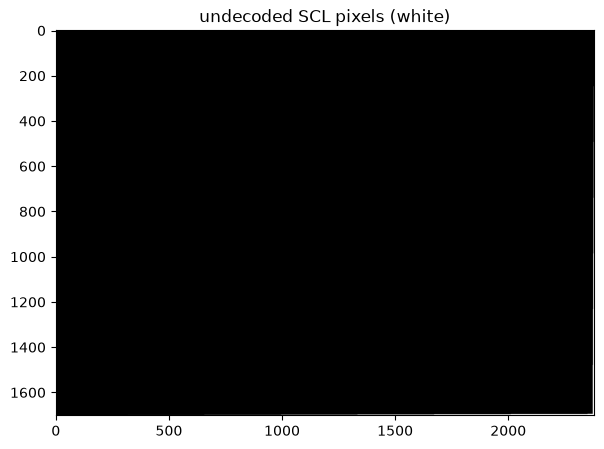

In [8]:
# Where are the undecoded pixels?
plt.figure(figsize=(8, 5)); plt.imshow(scl == 255, cmap="gray"); plt.title("undecoded SCL pixels (white)"); plt.show()

The undecoded pixels form a thin frame around the image, where there is no image data. The export gave this frame the colour (2, 0, 0) instead of the legend's black. We therefore set them to **0 (no data)** and look at the class shares:

In [9]:
scl[scl == 255] = 0
pd.Series(scl.ravel()).map(SCL_NAMES).value_counts(normalize=True).mul(100).round(2)

not vegetated     76.24
vegetation        20.01
water              2.35
thin cirrus        0.65
no data            0.40
unclassified       0.29
dark area          0.05
cloud (medium)     0.01
Name: proportion, dtype: float64

**Question 2.** Why were some pixels not decoded, and how did you decide what to do with them? What share of the scene is 'not vegetated', vegetation and water, and how much is flagged as cloud or cirrus? Relate the result to the acquisition date.

*Your answer:*



## Step 3 · Check the grid, stack the bands, and see what resampling does  *(LO3)*

Before stacking bands into one array we must be sure that pixel (row, col) is **the same place on the ground in every band**. Here that is true because all bands share one grid, but we check it rather than assume it.

In [10]:
with rasterio.open(path("B04")) as ref:
    dst_transform, dst_crs = ref.transform, ref.crs
    dst_shape = (ref.height, ref.width)
print("reference grid:", dst_shape, dst_crs)
print(dst_transform)

bands = {}
for b in BANDS:
    with rasterio.open(path(b)) as src:
        # TODO: True only if the CRS, the shape (height, width) AND the transform equal those of the reference grid
        same_grid = (src.crs == dst_crs) and (src.shape == dst_shape) and (src.transform == dst_transform)
        if not same_grid:
            raise ValueError(f"{b} is on a different grid: it must be resampled first")
        a = src.read(1)
    a[a == 0] = np.nan                                   # 0 = the no-data frame
    bands[b] = a

stack = np.stack([bands[b] for b in BANDS])             # (bands, rows, cols)
print("stack:", stack.shape, "| NaN values per band:", int(np.isnan(stack[0]).sum()))

reference grid: (1702, 2380) EPSG:32736
| 19.98, 0.00, 163171.98|
| 0.00,-19.96, 9797057.64|
| 0.00, 0.00, 1.00|


C:\Users\user\AppData\Local\Temp\ipykernel_3648\1505246732.py:14: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  a = src.read(1)


stack: (12, 1702, 2380) | NaN values per band: 16081


**What if the grids did not match?** Then every layer must be **resampled** onto one target grid with `rasterio.warp.reproject`, and the resampling method matters. We try it here: first the red band (B04) onto a coarser **60 m grid** (the resolution of Sentinel-2's 60 m bands, exactly 3 × 3 of our pixels per new pixel), then the SCL onto a **30 m grid** (Landsat's resolution), whose pixel centres fall *between* ours.

60 m grid: (567, 793)
nearest vs average: mean difference 0.0068, 99th percentile 0.0304 (reflectance)


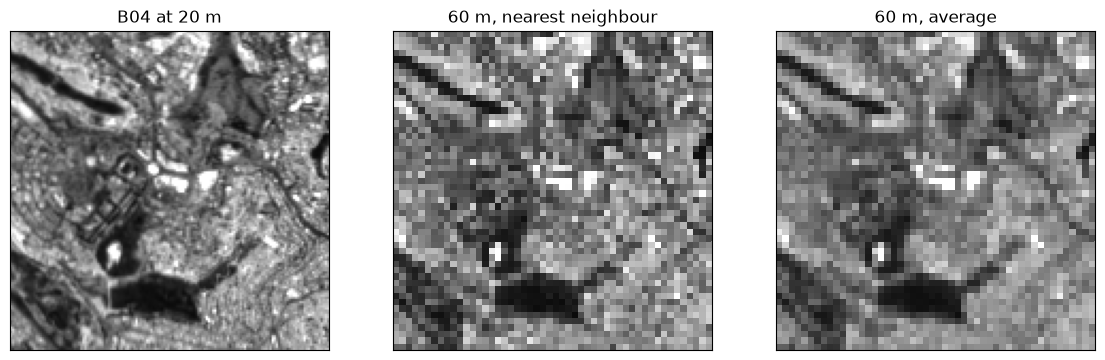

In [11]:
left, top = dst_transform.c, dst_transform.f
grid60 = from_origin(left, top, 3 * dst_transform.a, -3 * dst_transform.e)     # 60 m pixels, same corner
shape60 = (dst_shape[0] // 3, dst_shape[1] // 3)

def resample(array, method, out_shape=shape60, out_transform=grid60):
    """Resample a 2-D array from our 20 m grid onto another grid of the same CRS."""
    out = np.full(out_shape, np.nan, dtype="float32")
    reproject(source=array.astype("float32"), destination=out,
              src_transform=dst_transform, src_crs=dst_crs, dst_transform=out_transform, dst_crs=dst_crs,
              resampling=method, src_nodata=np.nan, dst_nodata=np.nan)
    return out

red_nearest = resample(bands["B04"], Resampling.nearest)     # keeps one of the 9 pixels
red_average = resample(bands["B04"], Resampling.average)     # mean of the 9 pixels
diff = np.abs(red_nearest - red_average)
print("60 m grid:", red_average.shape)
print(f"nearest vs average: mean difference {np.nanmean(diff):.4f}, 99th percentile {np.nanpercentile(diff, 99):.4f} (reflectance)")

zoom20, zoom60 = (slice(600, 750), slice(600, 750)), (slice(200, 250), slice(200, 250))    # the same 3 km x 3 km
fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
for a_, img, t in zip(ax, [bands["B04"][zoom20], red_nearest[zoom60], red_average[zoom60]],
                      ["B04 at 20 m", "60 m, nearest neighbour", "60 m, average"]):
    a_.imshow(img, cmap="gray", vmin=0.02, vmax=0.25); a_.set_title(t); a_.set_xticks([]); a_.set_yticks([])
plt.show()

In [13]:
# The SCL holds class CODES. What happens if we resample it like a continuous variable?
scl_nan = scl.astype("float32"); scl_nan[scl == 0] = np.nan
grid30 = from_origin(left, top, 30.0, 30.0)                                  # 30 m pixels, same corner
shape30 = (int(dst_shape[0] * -dst_transform.e // 30), int(dst_shape[1] * dst_transform.a // 30))
# TODO: resample scl_nan with the method that is correct for class codes, then with Resampling.bilinear
scl_nearest = resample(scl_nan, Resampling.nearest, shape30, grid30)
scl_bilinear = resample(scl_nan, Resampling.bilinear, shape30, grid30)
for name, s_ in [("nearest", scl_nearest), ("bilinear", scl_bilinear)]:
    v = s_[np.isfinite(s_)]
    print(f"{name:8s}: {100 * np.mean(v != np.round(v)):5.1f}% of 30 m pixels are not a whole class code; e.g. {np.unique(np.round(v, 1))[:10]}")

nearest :   0.0% of 30 m pixels are not a whole class code; e.g. [ 2.  4.  5.  6.  7.  8. 10.]
bilinear:  35.0% of 30 m pixels are not a whole class code; e.g. [2.  2.1 2.2 2.3 2.4 2.5 2.6 2.7 2.8 2.9]


Now the spectral indices, computed from the reflectance bands on the 20 m grid:

In [14]:
def nd(a, b):
    """Normalised difference (a - b) / (a + b), safe for zero denominators."""
    with np.errstate(divide="ignore", invalid="ignore"):
        return (a - b) / (a + b)

ndvi = nd(bands["B08"], bands["B04"])
# TODO: MNDWI = (green - SWIR1) / (green + SWIR1);  NDBI = (SWIR1 - NIR) / (SWIR1 + NIR)
mndwi = nd(bands["B03"], bands["B11"])
ndbi = nd(bands["B11"], bands["B08"])
for name, arr in [("NDVI", ndvi), ("MNDWI", mndwi), ("NDBI", ndbi)]:
    print(name, np.nanpercentile(arr, [1, 50, 99]).round(3))

NDVI [-0.19   0.312  0.729]
MNDWI [-0.616 -0.529  0.368]
NDBI [-0.299  0.068  0.24 ]


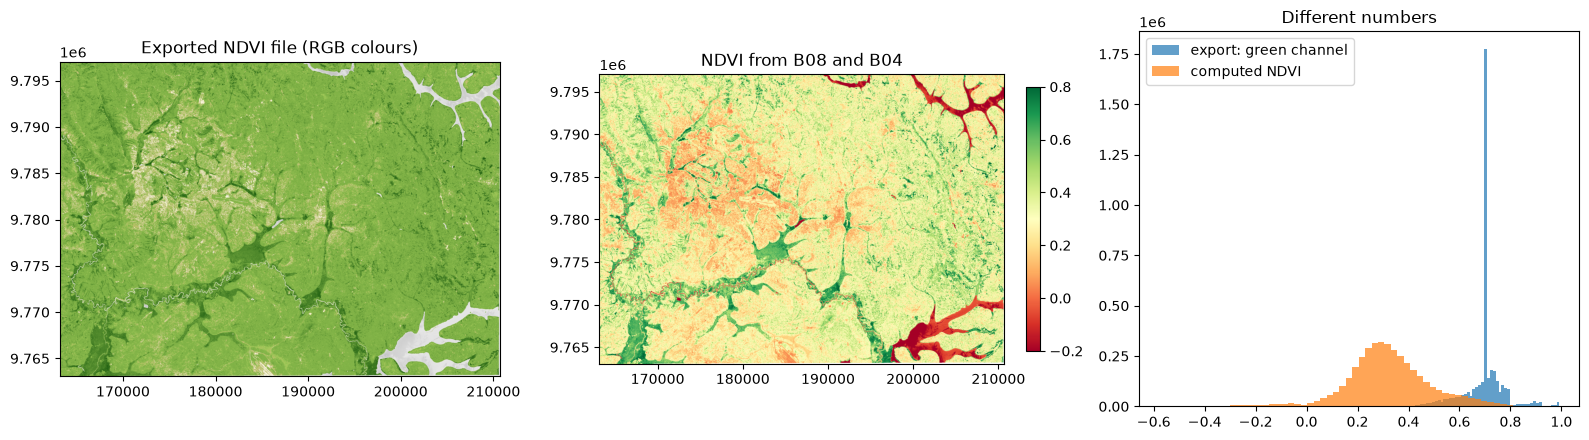

In [15]:
# Compare the exported 'NDVI' file (a colour picture) with NDVI computed from reflectance
with rasterio.open(path("NDVI")) as src:
    ndvi_export = src.read()                            # (3, rows, cols)
extent = plotting_extent(stack[0], dst_transform)       # (left, right, bottom, top) in metres

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].imshow(np.moveaxis(ndvi_export, 0, -1), extent=extent); ax[0].set_title("Exported NDVI file (RGB colours)")
im = ax[1].imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.8, extent=extent); ax[1].set_title("NDVI from B08 and B04")
plt.colorbar(im, ax=ax[1], fraction=0.03)
ax[2].hist(ndvi_export[1].ravel(), bins=60, alpha=0.7, label="export: green channel")
ax[2].hist(ndvi[np.isfinite(ndvi)].ravel(), bins=60, alpha=0.7, label="computed NDVI")
ax[2].legend(); ax[2].set_title("Different numbers")
plt.tight_layout(); plt.show()

**Question 3.** (a) Why must you check that bands share a grid before stacking them, even when their arrays have the same shape? (b) Going from 20 m to 60 m, which resampling method gives the better reflectance values, and why? (c) What went wrong when the SCL was resampled bilinearly? (d) Why must the exported NDVI file never be used as a feature?

*Your answer:*



## Step 4 · Build and check a validity mask  *(LO4)*

We flag pixels that should not enter the model: SCL classes 0 (no data), 1 (defective), 3 (cloud shadow), 8–9 (cloud) and 10 (thin cirrus), and any pixel whose reflectance is ≤ 0, > 1 or missing in any band.

In [16]:
INVALID_SCL = [ ]                        # TODO: list the SCL codes to mask
invalid_scl = np.isin(scl, INVALID_SCL)
bad_refl = np.any((bands[b] <= 0) | (bands[b] > 1) | np.isnan(bands[b]) for b in BANDS)
valid = ~invalid_scl & ~bad_refl

print(f"invalid by SCL: {invalid_scl.sum():,} | bad or missing reflectance: {bad_refl.sum():,}")
print(f"valid pixels: {valid.mean():.2%} | masked: {(~valid).sum():,} ({(~valid).mean():.2%})")

invalid by SCL: 0 | bad or missing reflectance: 1
valid pixels: 0.00% | masked: 4,050,760 (100.00%)


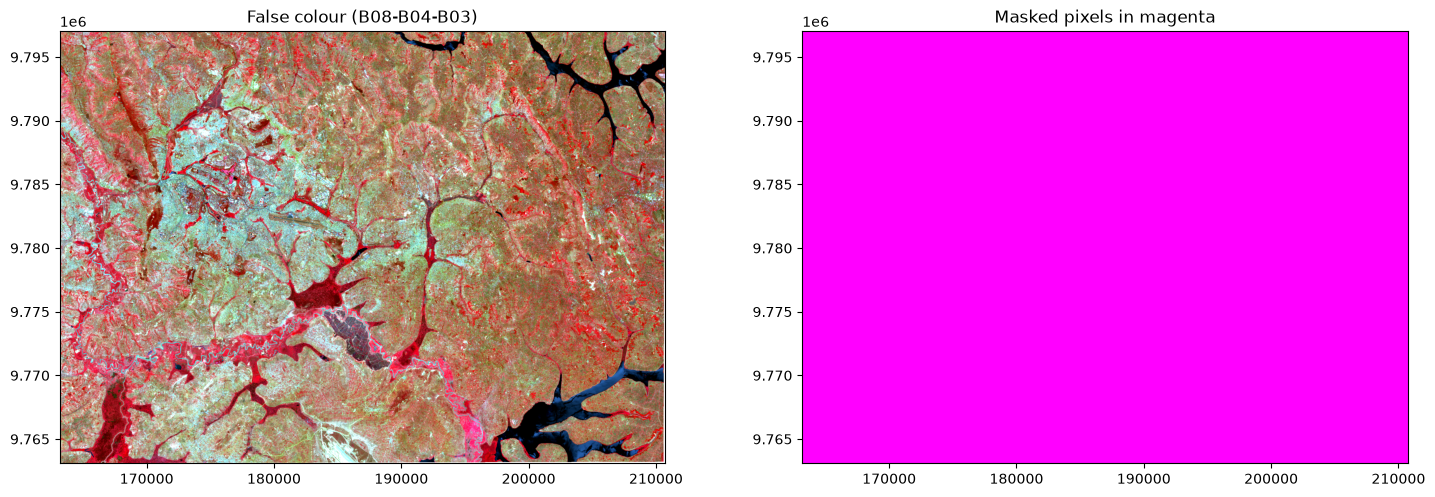

SCL classes present: {'no data': 16081, 'dark area': 2085, 'vegetation': 810677, 'not vegetated': 3088363, 'water': 95379, 'unclassified': 11621, 'cloud (medium)': 227, 'thin cirrus': 26327}


In [17]:
# Look before you trust: show masked pixels (magenta) on a false-colour composite
false_colour = np.dstack([stretch(bands["B08"]), stretch(bands["B04"]), stretch(bands["B03"])])
overlay = np.nan_to_num(false_colour.copy(), nan=1.0)
overlay[~valid] = [1, 0, 1]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].imshow(np.nan_to_num(false_colour, nan=1.0), extent=extent); ax[0].set_title("False colour (B08-B04-B03)")
ax[1].imshow(overlay, extent=extent); ax[1].set_title("Masked pixels in magenta")
plt.tight_layout(); plt.show()
print("SCL classes present:", {SCL_NAMES[int(k)]: int(v) for k, v in zip(*np.unique(scl, return_counts=True))})

**Question 4.** How many pixels did the mask remove, and which reasons dominate? Would you also mask SCL class 2 (dark area) and class 7 (unclassified)? Justify.

*Your answer:*



## Step 5 · Clean the reference data and bring it into the image's CRS  *(LO1, LO5)*

Reference data come as (a) a CSV of points with **latitude/longitude** columns (EPSG:4326) and (b) a GeoJSON of polygons in **UTM zone 36S** (EPSG:32736). Both must be cleaned and must be in the **same CRS as the image** before we can overlay them.

In [18]:
pts_raw = pd.read_csv(os.path.join(DATA_DIR, "kigali_reference_points.csv"))
print(pts_raw.shape)
print("class labels:", pts_raw["class"].unique())
print("exact duplicates:", pts_raw.duplicated().sum())
print("missing values:\n", pts_raw.isna().sum())

(175, 5)
class labels: <StringArray>
[            'water',  'dense vegetation', 'sparse vegetation',
          'Built-up',         'bare soil',          'built-up',
          'built up',            'Water ']
Length: 8, dtype: str
exact duplicates: 2
missing values:
 point_id    0
class       0
lat         1
lon         0
date        0
dtype: int64


In [19]:
pts = pts_raw.copy()
# TODO: harmonise labels (strip spaces, lower case, 'built up' -> 'built-up')
pts["class"] = pts["class"].str.strip().str.lower().str.replace(" ", "-")
# TODO: drop exact duplicates and rows with a missing lat or lon
pts = pts.drop_duplicates().dropna(subset=["lat", "lon"])
print("after cleaning labels, duplicates and missing coordinates:", len(pts))
print(pts["class"].value_counts())

after cleaning labels, duplicates and missing coordinates: 172
class
built-up             43
dense-vegetation     40
sparse-vegetation    40
bare-soil            26
water                23
Name: count, dtype: int64


In [20]:
# CSV -> points. x = longitude, y = latitude, CRS stated explicitly.
pts_gdf = gpd.GeoDataFrame(pts, geometry=gpd.points_from_xy(pts["lon"], pts["lat"]), crs="EPSG:4326")
print("points CRS:", pts_gdf.crs, "| image CRS:", dst_crs)
pts_gdf = pts_gdf.to_crs(dst_crs)                                         # TODO: reproject the points to the image CRS (hint: .to_crs)

left, bottom, right, top = extent[0], extent[2], extent[1], extent[3]
inside = pts_gdf.geometry.x.between(left, right) & pts_gdf.geometry.y.between(bottom, top)
print("points outside the image:\n", pts_gdf.loc[~inside, ["point_id", "class", "lat", "lon"]])
pts_gdf = pts_gdf[inside].copy()
print("usable points:", len(pts_gdf))

points CRS: EPSG:4326 | image CRS: EPSG:32736
points outside the image:
     point_id      class      lat      lon
172     P900  bare-soil  -2.3105  30.2011
173     P901   built-up  30.0712  -1.9453
usable points: 170


In [25]:
polys = gpd.read_file(os.path.join(DATA_DIR, "kigali_reference_polygons_utm36s.geojson"))
print("polygon CRS:", polys.crs, "| image CRS:", dst_crs, "| same:", polys.crs.to_epsg() == dst_crs.to_epsg())
print(len(polys), "polygons;", polys["class"].value_counts().to_dict())

polygon CRS: EPSG:32736 | image CRS: EPSG:32736 | same: True
49 polygons; {'dense vegetation': 12, 'built-up': 12, 'sparse vegetation': 9, 'water': 8, 'bare soil': 8}


C:\Users\user\AppData\Local\Temp\ipykernel_3648\1348958538.py:6: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  pts_gdf[pts_gdf["class"] == cl].plot(ax=ax, color=col, markersize=18, edgecolor="white", label=cl)
C:\Users\user\AppData\Local\Temp\ipykernel_3648\1348958538.py:6: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  pts_gdf[pts_gdf["class"] == cl].plot(ax=ax, color=col, markersize=18, edgecolor="white", label=cl)
C:\Users\user\AppData\Local\Temp\ipykernel_3648\1348958538.py:6: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  pts_gdf[pts_gdf["class"] == cl].plot(ax=ax, color=col, markersize=18, edgecolor="white", label=cl)


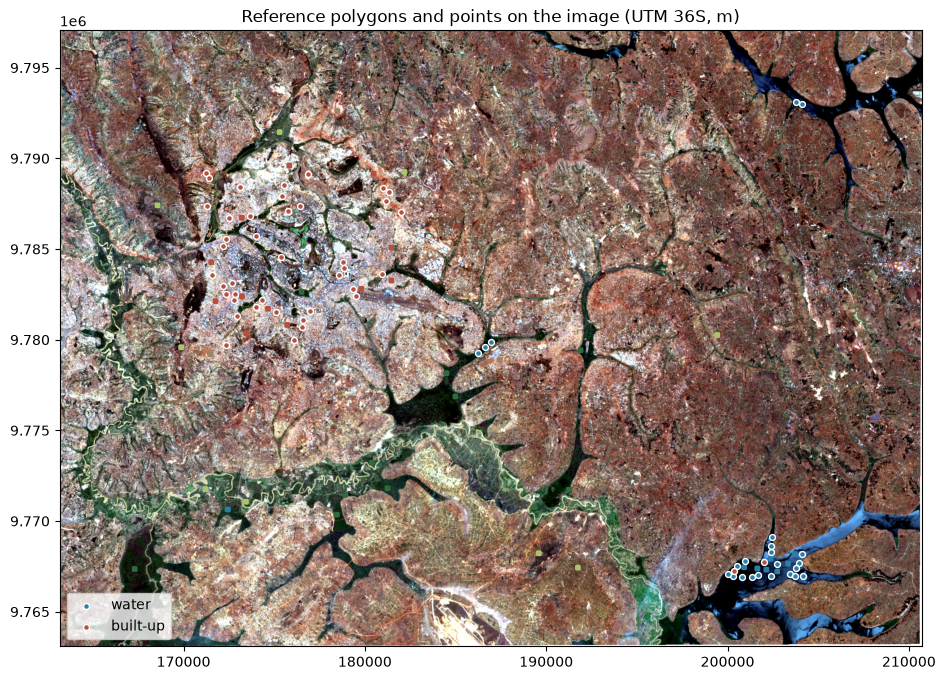

In [26]:
true_colour = np.nan_to_num(np.dstack([stretch(bands["B04"]), stretch(bands["B03"]), stretch(bands["B02"])]), nan=1.0)
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(true_colour, extent=extent)
for cl, col in CLASS_COLOURS.items():
    polys[polys["class"] == cl].plot(ax=ax, facecolor="none", edgecolor=col, linewidth=2)
    pts_gdf[pts_gdf["class"] == cl].plot(ax=ax, color=col, markersize=18, edgecolor="white", label=cl)
ax.legend(loc="lower left"); ax.set_title("Reference polygons and points on the image (UTM 36S, m)")
plt.show()

**Question 5.** List every problem you found in the CSV and how you handled it. Why did the points have to be reprojected but the polygons not? Why is the point with swapped latitude and longitude dangerous even though both of its numbers are valid coordinates?

*Your answer:*



## Step 6 · Extract pixel values  *(LO6)*

* **Points:** convert coordinates to (row, col) with the inverse affine transform and read the arrays.
* **Polygons:** every pixel whose centre lies inside the polygon becomes one row carrying the polygon's label and ID.

In [27]:
layers = {**{b: bands[b] for b in BANDS}, "NDVI": ndvi, "MNDWI": mndwi, "NDBI": ndbi}

# --- points
# TODO: convert point coordinates to pixel rows and columns (hint: rowcol(dst_transform, xs, ys))
r, c = rowcol(dst_transform, pts_gdf.geometry.x.values, pts_gdf.geometry.y.values)
r, c = np.asarray(r), np.asarray(c)
pt_table = pd.DataFrame({"source": "point", "group_id": pts_gdf["point_id"].values,
                         "class": pts_gdf["class"].values, "row": r, "col": c})
for name, arr in layers.items():
    pt_table[name] = arr[r, c]
pt_table["SCL"] = scl[r, c]; pt_table["valid"] = valid[r, c]
print("point rows:", len(pt_table))

point rows: 170


In [28]:
# --- polygons
parts = []
for _, p in polys.iterrows():
    # TODO: Boolean array, True inside this polygon (hint: geometry_mask(..., invert=True))
    inside = geometry_mask([p["geometry"]], transform=dst_transform, invert=True, out_shape=dst_shape)
    rr, cc = np.nonzero(inside)
    part = pd.DataFrame({"source": "polygon", "group_id": f"poly_{p['poly_id']}",
                         "class": p["class"], "row": rr, "col": cc})
    for name, arr in layers.items():
        part[name] = arr[rr, cc]
    part["SCL"] = scl[rr, cc]; part["valid"] = valid[rr, cc]
    parts.append(part)
poly_table = pd.concat(parts, ignore_index=True)
print("polygon rows:", len(poly_table))
print("pixels per polygon:", poly_table.groupby("group_id").size().describe()[["min", "mean", "max"]].round(1).to_dict())

polygon rows: 3331
pixels per polygon: {'min': 64.0, 'mean': 68.0, 'max': 81.0}


**Question 6.** How many rows did the points and the polygons give? Each polygon is about 165 m × 165 m: why does it give 64–81 pixels, and why are these rows **not** independent observations? What does `group_id` let you do later?

*Your answer:*



## Step 7 · Build the ML-ready table and explore it  *(LO7–8)*

In [29]:
FEATURES = BANDS + ["NDVI", "MNDWI", "NDBI"]
table = pd.concat([poly_table, pt_table], ignore_index=True)
n_before = len(table)
# TODO: keep only valid rows and drop rows with NaN in any feature
table = table[table["valid"]].dropna(subset=FEATURES).copy()
table.insert(0, "obs_id", np.arange(1, len(table) + 1))
print(f"rows: {n_before} -> {len(table)} after removing invalid pixels")
print(pd.crosstab(table["class"], table["source"]))

table.to_csv("kigali_training_table_L3.csv", index=False)
try:
    table.to_parquet("kigali_training_table_L3.parquet", index=False)
except Exception as e:
    print("Parquet not saved (install pyarrow):", e)
table.head()

rows: 3501 -> 0 after removing invalid pixels
Empty DataFrame
Columns: []
Index: []
Parquet not saved (install pyarrow): Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip or conda to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.


,obs_id,source,group_id,class,row,col,B01,B02,B03,B04,...,B08,B8A,B09,B11,B12,NDVI,MNDWI,NDBI,SCL,valid


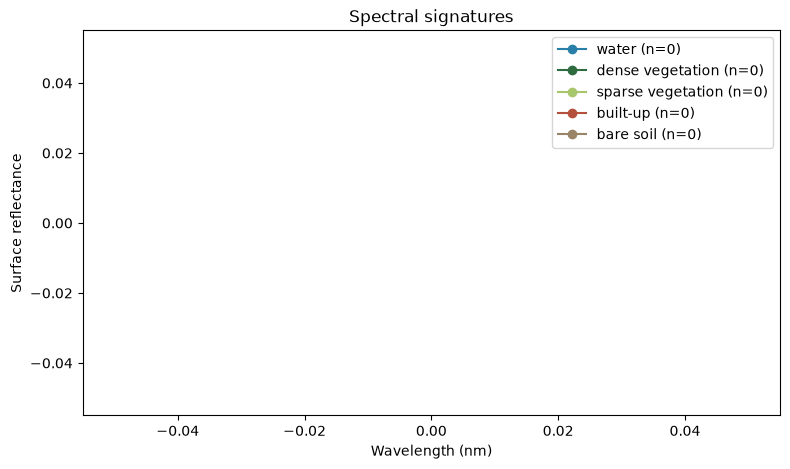

In [30]:
# EDA 1: spectral signatures (mean +/- 1 SD) per class
WAVELENGTH = {"B01": 443, "B02": 490, "B03": 560, "B04": 665, "B05": 705, "B06": 740, "B07": 783,
              "B08": 842, "B8A": 865, "B09": 945, "B11": 1610, "B12": 2190}
fig, ax = plt.subplots(figsize=(9, 5))
for cl, col in CLASS_COLOURS.items():
    d = table[table["class"] == cl]
    m, s = d[BANDS].mean().values, d[BANDS].std().values
    x = [WAVELENGTH[b] for b in BANDS]
    ax.plot(x, m, "o-", color=col, label=f"{cl} (n={len(d)})"); ax.fill_between(x, m - s, m + s, color=col, alpha=0.15)
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Surface reflectance"); ax.legend(); ax.set_title("Spectral signatures")
plt.show()

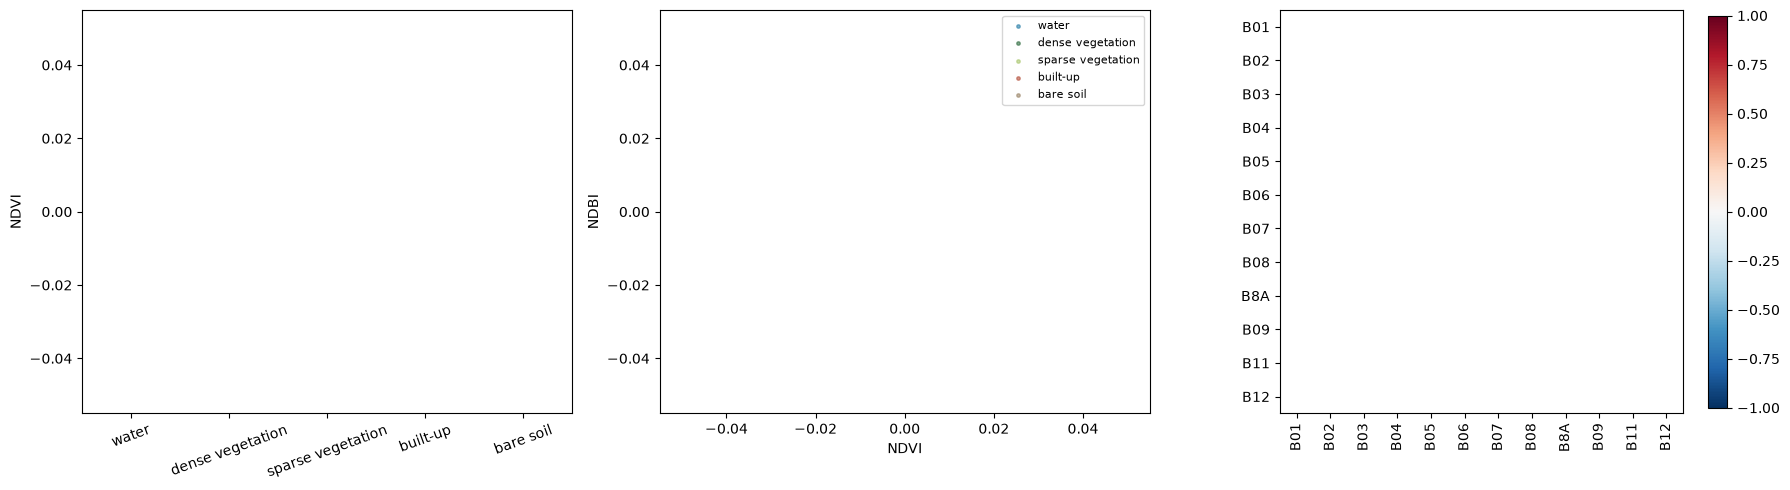

B08-B8A r = nan | B02-B03 r = nan | B04-B08 r = nan


In [31]:
# EDA 2: separability (NDVI box plots, NDVI-NDBI feature space) and EDA 3: band correlation
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
order = list(CLASS_COLOURS)
ax[0].boxplot([table.loc[table["class"] == c, "NDVI"] for c in order])
ax[0].set_xticks(range(1, len(order) + 1)); ax[0].set_xticklabels(order, rotation=20); ax[0].set_ylabel("NDVI")
for cl, col in CLASS_COLOURS.items():
    d = table[table["class"] == cl]; ax[1].scatter(d["NDVI"], d["NDBI"], s=6, color=col, label=cl, alpha=0.6)
ax[1].set_xlabel("NDVI"); ax[1].set_ylabel("NDBI"); ax[1].legend(fontsize=8)
corr = table[BANDS].corr()
im = ax[2].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax[2].set_xticks(range(len(BANDS))); ax[2].set_xticklabels(BANDS, rotation=90)
ax[2].set_yticks(range(len(BANDS))); ax[2].set_yticklabels(BANDS); plt.colorbar(im, ax=ax[2], fraction=0.04)
plt.tight_layout(); plt.show()
print("B08-B8A r = %.2f | B02-B03 r = %.2f | B04-B08 r = %.2f" % (corr.loc["B08", "B8A"], corr.loc["B02", "B03"], corr.loc["B04", "B08"]))

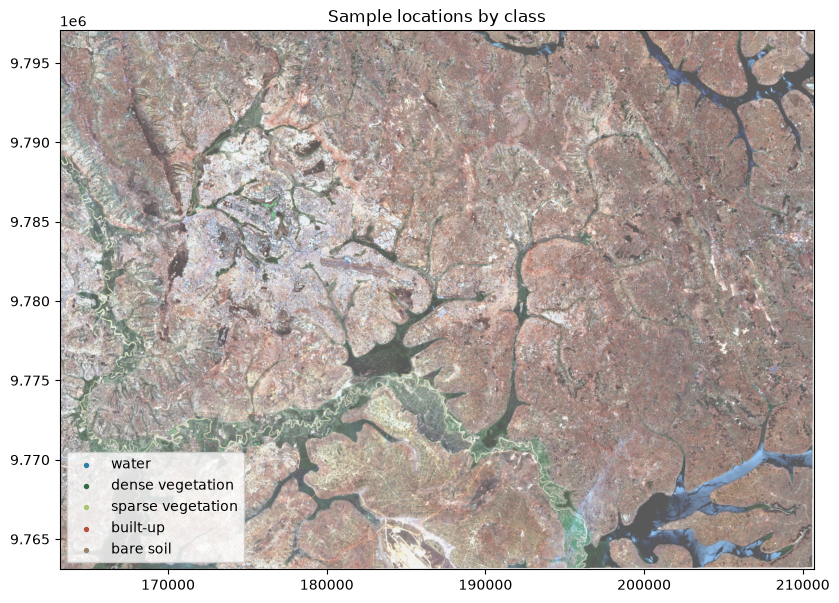

In [32]:
# EDA 4: where are the samples?
xs, ys = dst_transform * (table["col"].values + 0.5, table["row"].values + 0.5)
fig, ax = plt.subplots(figsize=(11, 7))
ax.imshow(np.clip(true_colour * 0.6 + 0.35, 0, 1), extent=extent)
for cl, col in CLASS_COLOURS.items():
    m = (table["class"] == cl).values
    ax.scatter(np.asarray(xs)[m], np.asarray(ys)[m], s=8, color=col, label=cl)
ax.legend(loc="lower left"); ax.set_title("Sample locations by class"); plt.show()

**Question 7.** (a) Which classes are clearly separable, and which will a model confuse? (b) Which pairs of bands carry almost the same information? (c) What does the sample map suggest about how well the model would work in unsampled parts of the scene?

*Your answer:*



## Step 8 · Extension: resample to a 30 m grid, and areas in m²  *(LO2–3)*

Landsat, the other big free archive, records at 30 m. To combine the two you would put Sentinel-2 onto a 30 m grid. Because our CRS is **projected** (UTM, metres), distances and areas can also be computed directly.

In [33]:
res30 = 30.0
# TODO: number of 30 m columns and rows needed to cover the image extent (hint: np.ceil of width / 30)
w30 = int(np.ceil((extent[1] - extent[0]) / res30))
h30 = int(np.ceil((extent[3] - extent[2]) / res30))
grid30 = from_origin(extent[0], extent[3], res30, res30)
b08_30 = resample(bands["B08"], Resampling.average, out_shape=(h30, w30), out_transform=grid30)
print("30 m grid:", b08_30.shape, "| pixel size:", grid30.a, "m")
print(f"image area with data: {np.isfinite(b08_30).sum() * res30 * res30 / 1e6:,.0f} km2")
print("polygon areas (m2):", polys.area.describe()[["min", "mean", "max"]].round(0).to_dict())

30 m grid: (1133, 1585) | pixel size: 30.0 m
image area with data: 1,610 km2
polygon areas (m2): {'min': 27413.0, 'mean': 27425.0, 'max': 27432.0}


**Question 8.** What is the area of the image in km² and of one reference polygon in m²? Why could we compute them directly here, and what would you have to do first if the image were in latitude/longitude (EPSG:4326)? Why is `average` a sensible choice when going from 20 m to 30 m?

*Your answer:*



## Reflection (submit in pairs)

1. Which problems in the Kigali files would **not** have produced an error message but would have produced a wrong model?
2. Write the 5–7 lines you would put in a README to document how your ML table was made.
3. The reference data were created from the image itself. Why does that make any accuracy you compute later optimistic? (Preview of Lecture 4.)

*Your answer:*

